# Tugas Lab 2: Pencarian Kemiripan Musik Menggunakan ANNOY, FAISS, dan HNSW

Percobaan penggunaan ANNOY, FAISS, dan HNSWLIB pada dataset `songs_with_attributes_and_lyrics.csv`:
1. **Load data dan inspect isi dataset CSV.**
2. **Pilih hanya fitur numerik saja, dan lakukan normalisasi menggunakan StandardScaler.**
3. **Lakukan pencarian track terdekat dan bandingkan hasilnya.**
4. **Lakukan perbandingan pada exact NN, ANNOY, FAISS, dan HNSW.**

# Langkah 1 - Load Dataset & Library

In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Load dataset songs_with_attributes_and_lyrics.csv
df = pd.read_csv('Dataset/songs_with_attributes_and_lyrics.csv')
df.head(3)

,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,HELLYEAH,0.415,0.6050,7,-11.157,1,0.0575,0.00116,0.838,0.471,0.193,100.059,79500.0,"He said he came from Jamaica,\n he owned a cou..."
1,2ASl4wirkeYm3OWZxXKYuq,!!,NaN,Yxngxr1,0.788,0.6480,7,-9.135,0,0.3150,0.90000,0.000,0.176,0.287,79.998,114000.0,"Fucked a bitch, now she running with my kids\n..."
2,69lcggVPmOr9cvPx9kLiiN,!!! - Interlude,Where I Belong EP,Glowie,0.000,0.0354,7,-20.151,0,0.0000,0.90800,0.000,0.479,0.000,0.000,11413.0,"Oh, my God, I'm going crazy\n"


In [2]:
# Informasi dataset
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 955320 entries, 0 to 955319
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                955320 non-null  str    
 1   name              955309 non-null  str    
 2   album_name        385557 non-null  str    
 3   artists           955315 non-null  str    
 4   danceability      955320 non-null  float64
 5   energy            955320 non-null  float64
 6   key               955320 non-null  str    
 7   loudness          955320 non-null  float64
 8   mode              955320 non-null  str    
 9   speechiness       955320 non-null  float64
 10  acousticness      955320 non-null  float64
 11  instrumentalness  955320 non-null  float64
 12  liveness          955320 non-null  float64
 13  valence           955320 non-null  float64
 14  tempo             955320 non-null  float64
 15  duration_ms       955320 non-null  float64
 16  lyrics            955307 non-nu

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,955320.000000,9.553200e+05
mean,0.550710,0.652442,-7.833732,0.083638,0.282962,0.081875,0.220190,0.488119,122.226093,2.341441e+05
std,0.169784,0.238824,3.792018,0.092929,0.311800,0.212789,0.195938,0.251468,29.536303,9.068368e+04
min,0.000000,0.000000,-60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.586000e+03
25%,0.436000,0.482000,-9.750000,0.034500,0.011900,0.000000,0.098900,0.282000,99.021000,1.849330e+05
50%,0.558000,0.687000,-7.041000,0.047800,0.142000,0.000039,0.137000,0.477000,120.661000,2.213070e+05
75%,0.675000,0.857000,-5.148000,0.087625,0.518000,0.008660,0.285000,0.690000,140.094000,2.656400e+05
max,0.993000,1.000000,4.882000,0.966000,0.996000,1.000000,1.000000,1.000000,246.130000,5.764624e+06


# Langkah 2 - Seleksi Fitur Numerik & Normalisasi dengan StandardScaler
Sesuai instruksi tugas, kita hanya memilih fitur-fitur audio numerik dan melakukan standardisasi menggunakan `StandardScaler`.

In [3]:
# Pilih hanya fitur numerik audio
features = ['danceability', 'energy', 'loudness', 'speechiness', 
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

# Pembersihan missing values pada fitur numerik
df_clean = df.dropna(subset=features).reset_index(drop=True)
X = df_clean[features].values.astype(np.float32)

# Standarisasi fitur menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype(np.float32)

k = 10  # jumlah nearest neighbors
print(f"Bentuk data fitur: {X_scaled.shape[0]} baris, {X_scaled.shape[1]} dimensi numerik")

Bentuk data fitur: 955320 baris, 9 dimensi numerik


# Langkah 3 - Pemilihan Query Track

In [4]:
# Menentukan 1 track query (contoh: track indeks ke-0)
query_idx = 0
query_vec = X_scaled[query_idx:query_idx+1]

query_title = df_clean.loc[query_idx, 'name']
query_artist = df_clean.loc[query_idx, 'artists']

print(f"Query Track [Index {query_idx}]: '{query_title}' oleh {query_artist}")
display(df_clean.loc[[query_idx], ['name', 'artists'] + features])

Query Track [Index 0]: '!' oleh HELLYEAH


,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,!,HELLYEAH,0.415,0.605,-11.157,0.0575,0.00116,0.838,0.471,0.193,100.059


# Langkah 4 - Pencarian dengan Exact NN (Brute Force Ground Truth)

In [5]:
# 1. Exact NN (Brute Force)
start = time.time()
exact_nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
exact_nn.fit(X_scaled)
exact_dists, exact_indices = exact_nn.kneighbors(query_vec)
exact_time = (time.time() - start) * 1000

print(f"Exact NN Selesai dalam {exact_time:.3f} ms")
print("Top 10 Indices:", exact_indices[0])
print("Top 10 Distances:", [round(d, 4) for d in exact_dists[0]])

Exact NN Selesai dalam 1632.686 ms
Top 10 Indices: [     0 394553 764272 837727 749223  61511 625227 833164 676733 523698]
Top 10 Distances: [np.float64(0.0), np.float64(0.8867), np.float64(0.9094), np.float64(0.936), np.float64(0.9376), np.float64(0.9465), np.float64(0.9763), np.float64(0.9954), np.float64(1.0208), np.float64(1.0408)]


# Langkah 5 - Pencarian dengan ANNOY

In [6]:
# 2. ANNOY
f = X_scaled.shape[1]
ann_index = AnnoyIndex(f, 'euclidean')

t0 = time.time()
for i in range(len(X_scaled)):
    ann_index.add_item(i, X_scaled[i])
ann_index.build(10)  # 10 pohon
ann_build_time = time.time() - t0

t0 = time.time()
ann_indices, ann_dists = ann_index.get_nns_by_vector(query_vec[0], k, include_distances=True)
ann_query_time = (time.time() - t0) * 1000

print(f"ANNOY Build: {ann_build_time:.3f}s | Query: {ann_query_time:.3f} ms")
print("Top 10 Indices:", ann_indices)
print("Top 10 Distances:", [round(d, 4) for d in ann_dists])

ANNOY Build: 3.816s | Query: 0.227 ms
Top 10 Indices: [0, 394553, 764272, 837727, 749223, 61511, 833164, 676733, 523698, 888081]
Top 10 Distances: [0.0, 0.8867, 0.9094, 0.936, 0.9376, 0.9465, 0.9954, 1.0208, 1.0408, 1.0485]


# Langkah 6 - Pencarian dengan FAISS (IVF-Flat Index)

In [7]:
# 3. FAISS IVF-Flat
nlist = 100
quantizer = faiss.IndexFlatL2(f)
faiss_ivf = faiss.IndexIVFFlat(quantizer, f, nlist, faiss.METRIC_L2)

t0 = time.time()
faiss_ivf.train(X_scaled)
faiss_ivf.add(X_scaled)
faiss_build_time = time.time() - t0

faiss_ivf.nprobe = 10  # jumlah centroid terdekat yang dicari
t0 = time.time()
faiss_dists, faiss_indices = faiss_ivf.search(query_vec, k)
faiss_query_time = (time.time() - t0) * 1000

print(f"FAISS IVF Build: {faiss_build_time:.3f}s | Query: {faiss_query_time:.3f} ms")
print("Top 10 Indices:", faiss_indices[0])
print("Top 10 Distances:", [round(np.sqrt(d), 4) for d in faiss_dists[0]])

FAISS IVF Build: 0.426s | Query: 1.685 ms
Top 10 Indices: [     0 394553 764272 837727 749223  61511 625227 833164 676733 523698]
Top 10 Distances: [np.float32(0.0), np.float32(0.8867), np.float32(0.9094), np.float32(0.936), np.float32(0.9376), np.float32(0.9465), np.float32(0.9763), np.float32(0.9954), np.float32(1.0208), np.float32(1.0408)]


# Langkah 7 - Pencarian dengan HNSW (hnswlib)

In [8]:
# 4. HNSW
hnsw_p = hnswlib.Index(space='l2', dim=f)

t0 = time.time()
hnsw_p.init_index(max_elements=len(X_scaled), ef_construction=100, M=16)
hnsw_p.add_items(X_scaled)
hnsw_build_time = time.time() - t0

hnsw_p.set_ef(50)
t0 = time.time()
hnsw_indices, hnsw_dists = hnsw_p.knn_query(query_vec, k=k)
hnsw_query_time = (time.time() - t0) * 1000

print(f"HNSW Build: {hnsw_build_time:.3f}s | Query: {hnsw_query_time:.3f} ms")
print("Top 10 Indices:", hnsw_indices[0])
print("Top 10 Distances:", [round(np.sqrt(d), 4) for d in hnsw_dists[0]])

HNSW Build: 11.122s | Query: 0.263 ms
Top 10 Indices: [     0 394553 764272 837727 749223  61511 625227 833164 676733 523698]
Top 10 Distances: [np.float32(0.0), np.float32(0.8867), np.float32(0.9094), np.float32(0.936), np.float32(0.9376), np.float32(0.9465), np.float32(0.9763), np.float32(0.9954), np.float32(1.0208), np.float32(1.0408)]


# Langkah 8 - Perbandingan Hasil Rekomendasi Lagu & Evaluasi Performansi
Membandingkan track terdekat yang ditemukan oleh masing-masing metode beserta evaluasi waktu eksekusi dan recall terhadap Exact NN.

In [9]:
def get_track_info(indices, distances):
    df_res = df_clean.loc[indices, ['name', 'artists']].copy()
    df_res['distance'] = [round(float(d), 4) for d in distances]
    return df_res.reset_index(drop=True)

print("=== HASIL TRACK TERDEKAT: EXACT NN ===")
display(get_track_info(exact_indices[0], exact_dists[0]))

print("\n=== HASIL TRACK TERDEKAT: ANNOY ===")
display(get_track_info(ann_indices, ann_dists))

print("\n=== HASIL TRACK TERDEKAT: FAISS IVF ===")
display(get_track_info(faiss_indices[0], [np.sqrt(d) for d in faiss_dists[0]]))

print("\n=== HASIL TRACK TERDEKAT: HNSW ===")
display(get_track_info(hnsw_indices[0], [np.sqrt(d) for d in hnsw_dists[0]]))

# Menghitung Recall terhadap Exact NN
gt_set = set(exact_indices[0])
recall_exact = 1.000
recall_ann = len(set(ann_indices) & gt_set) / k
recall_faiss = len(set(faiss_indices[0]) & gt_set) / k
recall_hnsw = len(set(hnsw_indices[0]) & gt_set) / k

# Tabel Perbandingan Ringkas
perf_df = pd.DataFrame([
    {"Metode": "Exact NN (Brute)", "Build Time (s)": "-", "Query Time (ms)": f"{exact_time:.3f}", "Recall@10": f"{recall_exact:.3f}", "Percepatan": "1.0x"},
    {"Metode": "ANNOY (10 trees)", "Build Time (s)": f"{ann_build_time:.3f}", "Query Time (ms)": f"{ann_query_time:.3f}", "Recall@10": f"{recall_ann:.3f}", "Percepatan": f"{exact_time/ann_query_time:.1f}x"},
    {"Metode": "FAISS (IVF-100)", "Build Time (s)": f"{faiss_build_time:.3f}", "Query Time (ms)": f"{faiss_query_time:.3f}", "Recall@10": f"{recall_faiss:.3f}", "Percepatan": f"{exact_time/faiss_query_time:.1f}x"},
    {"Metode": "HNSW (M=16, ef=50)", "Build Time (s)": f"{hnsw_build_time:.3f}", "Query Time (ms)": f"{hnsw_query_time:.3f}", "Recall@10": f"{recall_hnsw:.3f}", "Percepatan": f"{exact_time/hnsw_query_time:.1f}x"}
])

print("\n=== TABEL PERBANDINGAN PERFORMANSI ===")
display(perf_df)

=== HASIL TRACK TERDEKAT: EXACT NN ===


,name,artists,distance
0,!,HELLYEAH,0.0000
1,Intro (Who The Fuck Are You'),C-Lekktor,0.8867
2,Testimonium,Lacrimosa,0.9094
3,Ultimate Satisfaction - The Field Remix,Bear In Heaven,0.9360
4,Sæglópur,Sigur Rós,0.9376
5,Autumn Interlude,Amethystium,0.9465
6,Púrpura,Margaritas Podridas,0.9763
7,Turn from Heaven,Therion,0.9954
8,See You When I Die,BOYO,1.0208
9,Mrityu,Multani;Karun;Udbhav,1.0408



=== HASIL TRACK TERDEKAT: ANNOY ===


,name,artists,distance
0,!,HELLYEAH,0.0000
1,Intro (Who The Fuck Are You'),C-Lekktor,0.8867
2,Testimonium,Lacrimosa,0.9094
3,Ultimate Satisfaction - The Field Remix,Bear In Heaven,0.9360
4,Sæglópur,Sigur Rós,0.9376
5,Autumn Interlude,Amethystium,0.9465
6,Turn from Heaven,Therion,0.9954
7,See You When I Die,BOYO,1.0208
8,Mrityu,Multani;Karun;Udbhav,1.0408
9,Who Makes the Nazis? - Live - Bonus Track,The Fall,1.0485



=== HASIL TRACK TERDEKAT: FAISS IVF ===


,name,artists,distance
0,!,HELLYEAH,0.0000
1,Intro (Who The Fuck Are You'),C-Lekktor,0.8867
2,Testimonium,Lacrimosa,0.9094
3,Ultimate Satisfaction - The Field Remix,Bear In Heaven,0.9360
4,Sæglópur,Sigur Rós,0.9376
5,Autumn Interlude,Amethystium,0.9465
6,Púrpura,Margaritas Podridas,0.9763
7,Turn from Heaven,Therion,0.9954
8,See You When I Die,BOYO,1.0208
9,Mrityu,Multani;Karun;Udbhav,1.0408



=== HASIL TRACK TERDEKAT: HNSW ===


,name,artists,distance
0,!,HELLYEAH,0.0000
1,Intro (Who The Fuck Are You'),C-Lekktor,0.8867
2,Testimonium,Lacrimosa,0.9094
3,Ultimate Satisfaction - The Field Remix,Bear In Heaven,0.9360
4,Sæglópur,Sigur Rós,0.9376
5,Autumn Interlude,Amethystium,0.9465
6,Púrpura,Margaritas Podridas,0.9763
7,Turn from Heaven,Therion,0.9954
8,See You When I Die,BOYO,1.0208
9,Mrityu,Multani;Karun;Udbhav,1.0408



=== TABEL PERBANDINGAN PERFORMANSI ===


,Metode,Build Time (s),Query Time (ms),Recall@10,Percepatan
0,Exact NN (Brute),-,1632.686,1.000,1.0x
1,ANNOY (10 trees),3.816,0.227,0.900,7185.7x
2,FAISS (IVF-100),0.426,1.685,1.000,969.0x
3,"HNSW (M=16, ef=50)",11.122,0.263,1.000,6208.5x


# Langkah 9 - Visualisasi Perbandingan Latensi Query & Build Time

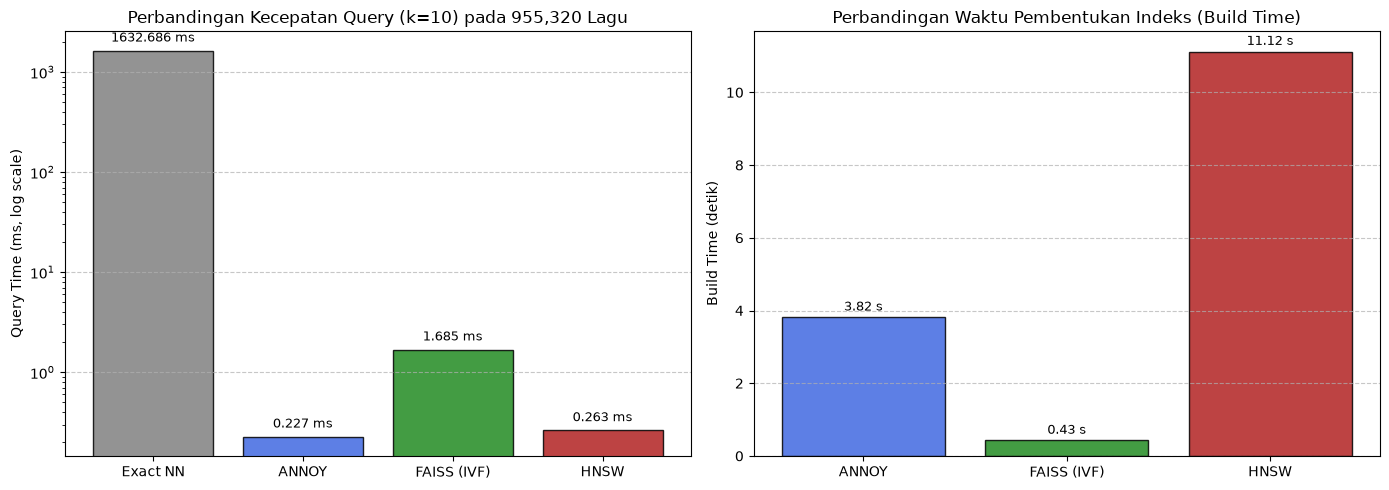

In [10]:
# Visualisasi Waktu Query dan Build Time
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
methods = ['Exact NN', 'ANNOY', 'FAISS (IVF)', 'HNSW']
q_times = [exact_time, ann_query_time, faiss_query_time, hnsw_query_time]
b_times = [0, ann_build_time, faiss_build_time, hnsw_build_time]
colors = ['gray', 'royalblue', 'forestgreen', 'firebrick']

# 1. Query Latency
bars1 = axes[0].bar(methods, q_times, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_ylabel('Query Time (ms, log scale)')
axes[0].set_yscale('log')
axes[0].set_title(f'Perbandingan Kecepatan Query (k={k}) pada {len(df_clean):,} Lagu')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval * 1.15, f'{yval:.3f} ms', ha='center', va='bottom', fontsize=9)

# 2. Build Time
bars2 = axes[1].bar(methods[1:], b_times[1:], color=colors[1:], edgecolor='black', alpha=0.85)
axes[1].set_ylabel('Build Time (detik)')
axes[1].set_title('Perbandingan Waktu Pembentukan Indeks (Build Time)')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.1, f'{yval:.2f} s', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()